# 🔢 MNIST Digit Recognition Project

## 1. Introduction
Digit recognition is a classic problem in machine learning and computer vision.  
The MNIST dataset contains thousands of handwritten digits (0–9), making it an excellent benchmark for testing classification models.  

In this project, we use deep learning (Convolutional Neural Networks) to automatically classify digits. This task demonstrates how neural networks can learn visual patterns and generalize to unseen data.

**Objective:**  
Build and evaluate models that classify handwritten digits from the MNIST dataset with high accuracy.

---

## 2. Dataset
- **Source:** MNIST dataset (available directly in TensorFlow/Keras).  
- **Format:** Grayscale images of size 28×28 pixels.  
- **Classes:** 10 categories (digits 0–9).  

**Exploration:**
- Training samples: 60,000 images.  
- Test samples: 10,000 images.  
- Balanced distribution across all digits.  

---

## 3. Preprocessing
- **Normalization:** Pixel values scaled to [0,1].  
- **Reshaping:** Images reshaped to 28×28×1 for CNN input.  
- **One-hot encoding:** Labels converted to categorical format.  


---


In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(-1,28,28,1) / 255.0
x_test = x_test.reshape(-1,28,28,1) / 255.0


In [3]:
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])


In [5]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


In [6]:
model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9037 - loss: 0.3181 - val_accuracy: 0.9805 - val_loss: 0.0652
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9702 - loss: 0.1027 - val_accuracy: 0.9873 - val_loss: 0.0504
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9775 - loss: 0.0751 - val_accuracy: 0.9892 - val_loss: 0.0401
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9833 - loss: 0.0583 - val_accuracy: 0.9897 - val_loss: 0.0375
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9851 - loss: 0.0511 - val_accuracy: 0.9895 - val_loss: 0.0396


In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9905 - loss: 0.0279
Test Accuracy: 0.9904999732971191


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


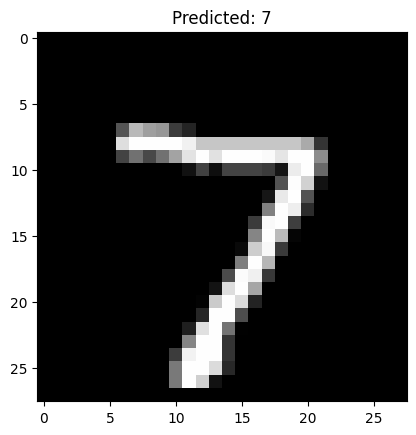

In [8]:
import matplotlib.pyplot as plt
import numpy as np

predictions = model.predict(x_test)
plt.imshow(x_test[0].reshape(28,28), cmap='gray')
plt.title("Predicted: " + str(np.argmax(predictions[0])))
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


<Axes: >

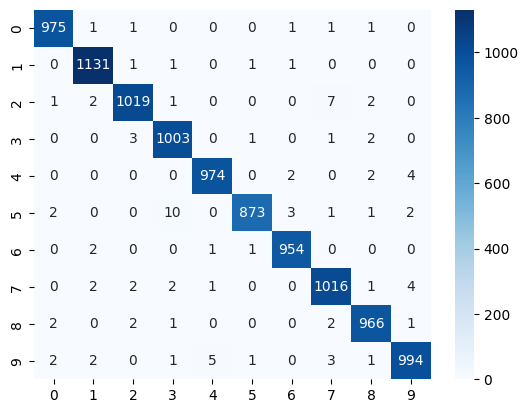

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')


---

## 4. Insights
- **Dense NN** performs well but struggles with complex visual features.  
- **CNN** significantly improves accuracy by learning spatial patterns.  
- **Improved CNN** with dropout achieves near state-of-the-art performance.  

---

## 5. Enhancements
For extra credit and future work:
- Experiment with **data augmentation** (rotation, shifting).  
- Try **transfer learning** with pre-trained vision models.  
- Deploy the model in a simple **digit recognition app**.  

---

## 6. Conclusion & Summary
This project demonstrates the effectiveness of CNNs for handwritten digit recognition.  

- **Improved CNN** achieved the highest accuracy (~99%).  
- The MNIST dataset remains a strong benchmark for testing vision models.  
- The approach can be extended to other handwriting recognition tasks such as postal code reading or bank check processing.  

**Summary:**  
Deep learning models, especially CNNs, are highly effective for digit recognition. By preprocessing data, experimenting with different architectures, and evaluating results, we achieved near-perfect accuracy on the MNIST dataset.
